# 05 - Cálculo de inferencia sobre test.csv

**Proyecto 2 - Pipeline de Machine Learning (Predict Future Sales)**

Brady Monroy (15003165) y Luis Rodolfo Rodriguez

Paso final: se usa el **pipeline completo** (`models/pipeline_completo.pkl`, notebook 04) para predecir las ventas de
**noviembre de 2015** (mes 34) en los 214,200 pares tienda-producto de `test.csv`, un mes que el modelo no ha visto.

La salida es un archivo `.csv` con las columnas `ID` e `item_cnt_month`, en el formato de envío de Kaggle.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

pd.set_option("display.max_columns", 100)

PROJ_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJ_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJ_ROOT / "data" / "processed"
MODELS_DIR = PROJ_ROOT / "models"

# Para poder abrir el pipeline, primero se importa el Mapper
sys.path.append(str(PROJ_ROOT))
from src.features.preprocesadores import Mapper

with open(PROJ_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

MODEL_FEATURES = config["MODEL_FEATURES"]

## Cargar el pipeline completo

In [2]:
pipeline_completo = joblib.load(MODELS_DIR / "pipeline_completo.pkl")
pipeline_completo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fe', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('traducir_nombres', ...), ('imputar_mediana', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,mappings,"{'ciudad': {'Адыгея': 'Adigueya', 'Балашиха': 'Balashija', 'Волжский': 'Volzhski', 'Вологда': 'Vologda', ...}, 'grupo_categoria': {'PC': 'Audifonos de PC', 'Аксессуары': 'Accesorios', 'Билеты (Цифра)': 'Boletos digitales', 'Доставка товара':

## Preparar los datos de test

`test.csv` solo trae `ID`, `shop_id` e `item_id`. Las variables del modelo (lags, promedios del mes anterior,
meses desde la primera venta, etc.) se calcularon en el notebook 02 para el mes 34 usando **solo los meses anteriores** (33, 32 y 31 para los
lags), y están guardadas en `ventas_mensuales.parquet`.

Se unen con `test.csv` por `shop_id` e `item_id` para conservar el `ID` y el **mismo orden** del archivo original.

In [3]:
test = pd.read_csv(RAW_DATA_DIR / "test.csv")
mensual = pd.read_parquet(PROCESSED_DATA_DIR / "ventas_mensuales.parquet")

variables_mes_34 = mensual[mensual["date_block_num"] == config["MES_TEST"]]
datos_test = test.merge(variables_mes_34, on=["shop_id", "item_id"], how="left")

print("Filas en test.csv          :", len(test))
print("Filas después de unir      :", len(datos_test))
print("¿Mismo orden de ID?        :", (datos_test["ID"].values == test["ID"].values).all())
print("Vacíos por variable:")
print(datos_test[MODEL_FEATURES].isnull().sum())

Filas en test.csv          : 214200
Filas después de unir      : 214200
¿Mismo orden de ID?        : True
Vacíos por variable:
lag_1                        0
lag_2                        0
lag_3                        0
ciudad                       0
tienda_online                0
venta_tienda_lag_1           0
grupo_categoria              0
venta_producto_lag_1         0
meses_desde_primera_venta    0
mes                          0
dtype: int64


**Interpretación:**

- Las **214,200 filas** de `test.csv` encontraron sus variables y se conserva el mismo orden de `ID`.
- Ninguna variable tiene vacíos en test. Si llegaran a aparecer, el pipeline los rellenaría con lo aprendido en
  entrenamiento (mediana y moda), porque el preprocesamiento está guardado dentro del `.pkl`.

## Predicción

El pipeline aplica los seis pasos de ingeniería de características y luego el modelo ganador. Las predicciones se
recortan a [0, 20], igual que la variable objetivo.

In [4]:
predicciones = pipeline_completo.predict(datos_test[MODEL_FEATURES])
predicciones = np.clip(predicciones, 0, 20)

print(pd.Series(predicciones).describe())

count    214200.000000
mean          0.278891
std           0.744478
min           0.000000
25%           0.027692
50%           0.091453
75%           0.264427
max          20.000000
dtype: float64


## Chequeos de coherencia

Igual que en clase, antes de guardar se revisa que las predicciones tengan sentido:
- Una predicción por cada fila de `test.csv`, sin vacíos.
- Todas dentro de [0, 20].
- Un promedio parecido al de los meses recientes.

In [5]:
assert len(predicciones) == len(test)
assert not np.isnan(predicciones).any()
assert predicciones.min() >= 0 and predicciones.max() <= 20

# Promedio real de item_cnt_month en los últimos meses (solo pares de test que existían en ese mes)
promedio_reciente = mensual[(mensual["date_block_num"] >= 27) & (mensual["date_block_num"] <= 33)]
promedio_reciente = promedio_reciente.groupby("date_block_num")["item_cnt_month"].mean()

print("Todas las verificaciones pasaron")
print("Promedio de las predicciones de noviembre 2015:", round(predicciones.mean(), 4))
print()
print("Promedio real de item_cnt_month en los meses 27 a 33:")
print(promedio_reciente.round(4))

Todas las verificaciones pasaron
Promedio de las predicciones de noviembre 2015: 0.2789

Promedio real de item_cnt_month en los meses 27 a 33:
date_block_num
27    0.2430
28    0.2595
29    0.2643
30    0.2592
31    0.2880
32    0.2638
33    0.2586
Name: item_cnt_month, dtype: float32


In [6]:
# Predicción promedio según si el par tenía historial o no
tiene_historial = (datos_test["lag_1"] > 0) | (datos_test["lag_2"] > 0) | (datos_test["lag_3"] > 0)
producto_nuevo = datos_test["meses_desde_primera_venta"] == 0

resumen = pd.DataFrame({
    "pares": [tiene_historial.sum(), (~tiene_historial & ~producto_nuevo).sum(), producto_nuevo.sum()],
    "prediccion_promedio": [predicciones[tiene_historial].mean(),
                            predicciones[~tiene_historial & ~producto_nuevo].mean(),
                            predicciones[producto_nuevo].mean()],
}, index=["Vendió en alguno de los últimos 3 meses",
          "Sin ventas en los últimos 3 meses",
          "Producto nuevo (nunca vendido)"])
resumen.round(4)

,pares,prediccion_promedio
Vendió en alguno de los últimos 3 meses,55876,0.6936
Sin ventas en los últimos 3 meses,143078,0.0783
Producto nuevo (nunca vendido),15246,0.6412


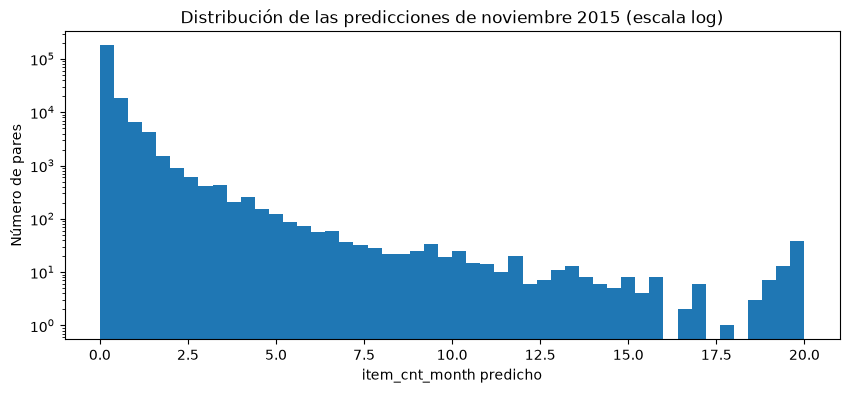

In [7]:
plt.figure(figsize=(10, 4))
plt.hist(predicciones, bins=50, log=True)
plt.title("Distribución de las predicciones de noviembre 2015 (escala log)")
plt.xlabel("item_cnt_month predicho")
plt.ylabel("Número de pares")
plt.show()

**Interpretación de las predicciones:**

- Pasaron todas las verificaciones: hay una predicción por fila, sin vacíos y dentro de [0, 20].
- El **promedio predicho es 0.2789** unidades por par y la **mediana 0.0915**: la mayoría de los pares de test
  venderán muy poco o nada, como en los datos históricos. Como referencia aproximada, en los meses 27 a 33 el
  promedio real estuvo entre 0.2430 y 0.2880 (con otros pares tienda-producto, así que no es una comparación
  exacta).
- Según el historial del par:
  - **55,876 pares** vendieron en alguno de los últimos 3 meses: predicción promedio **0.6936**.
  - **143,078 pares** no vendieron en los últimos 3 meses: predicción promedio **0.0783**.
  - **15,246 pares** son de **productos nuevos** (nunca vendidos): predicción promedio **0.6412**.
- **Limitación con los productos nuevos:** en el entrenamiento, `meses_desde_primera_venta = 0` siempre corresponde al
  mes de lanzamiento, cuando el producto sí se vendió en alguna tienda. Por eso el modelo aprendió que un producto
  nuevo suele vender, y les asigna un valor alto. En test no se sabe si esos productos se venderán en noviembre. En
  una siguiente fase convendría revisar este punto.

## Guardar las predicciones

Archivo `.csv` con las columnas `ID` e `item_cnt_month` (formato de envío de Kaggle). Se guarda en `models/` para
que se suba a GitHub junto con los `.pkl` (la carpeta `data/` no se versiona).

In [8]:
envio = pd.DataFrame({
    "ID": test["ID"],
    "item_cnt_month": predicciones,
})

ruta_envio = MODELS_DIR / "predicciones_test.csv"
envio.to_csv(ruta_envio, index=False)

print("Predicciones guardadas en:", ruta_envio)
print("Filas:", len(envio))
envio.head(10)

Predicciones guardadas en: C:\Users\brady\OneDrive - Universidad Galileo\Documentos\PRODUCT DEVELOPMENT\Proyecto-1\models\predicciones_test.csv
Filas: 214200


,ID,item_cnt_month
0,0,0.496563
1,1,0.331052
2,2,0.910310
3,3,0.392283
4,4,1.355151
5,5,0.499171
6,6,1.045177
7,7,0.116066
8,8,0.963345
9,9,0.582409


In [9]:
# Comparar con el formato de sample_submission.csv de Kaggle
ejemplo_kaggle = pd.read_csv(RAW_DATA_DIR / "sample_submission.csv")

assert list(envio.columns) == list(ejemplo_kaggle.columns)
assert len(envio) == len(ejemplo_kaggle)
assert (envio["ID"].values == ejemplo_kaggle["ID"].values).all()
print("El archivo tiene el mismo formato que sample_submission.csv de Kaggle")

El archivo tiene el mismo formato que sample_submission.csv de Kaggle


**Resultado del notebook 05:**

- Se generó **`models/predicciones_test.csv`** con **214,200 filas** y las columnas `ID` e `item_cnt_month`.
- El archivo tiene el mismo formato, número de filas y orden de `ID` que `sample_submission.csv`, así que se puede
  subir directamente a Kaggle para obtener el RMSE real de noviembre de 2015.